# Lake Pontchartrain: Hydromet Forcing Builder for Delft3D-FM

This notebook prepares boundary and meteorological forcing files for the Lake Pontchartrain Delft3D-FM model. It assembles one consistent hourly dataset for each run year and writes the final model input files.

This code creates the input files for the Delft3D-FM model of Lake Pontchartrain Estuary in Louisisna. 
It fives the option to add validate for water level, salinity, and tempeature. Note that for temperature,
we have found that compositie themperature has to be used over transport due to 


discharge, water level, wind, and atmospheric pressure as well as adds salinity boundary forcing, and adds temperature boundary forcing and composite meteo fields.

**Primary inputs:**
- Spillway discharge CSV in `outputs/bcs/`.
- Tributary discharge from USGS NWIS.
- Ocean boundary water level from NOAA CO-OPS.
- Salinity and water temperature from USGS and NOAA backups (when enabled).
- Wind, pressure, and composite meteorology from Open-Meteo ERA5.

**Outputs (written per year):**
- `outputs/dfm_forcings/<year>/` with `.bc` and `.tim` forcing files.
- QA tables in `outputs/tables/`.
- QA figures in `outputs/figures/`.

**How to run:**
- Set years, window, toggles, and site settings in Section 1.
- Run all cells top to bottom.
- Copy the generated forcing files into the Delft3D-FM model input folder.

## 1. Upload Packages

In [1]:
import json
import urllib.request as ureq
import urllib.parse as uparse
import urllib.error as uerr
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
import cmocean
from dataretrieval import nwis
from noaa_coops import Station
from scipy.signal import butter, filtfilt
from pvlib.location import Location
import openpyxl

## 1. Run Dates and Settings

Set the years, window, toggles, stations, boundaries, and output paths in this section.

If you need to change where data comes from, this is where you do it.

In [2]:
NB_DIR = Path.cwd()
PROJECT_ROOT = Path.cwd().parent

# --- Edit these run controls for each new run ---
RUN_YEARS = [2017]  # Multiple years can be included, e.g., [2013, 2014, 2015]
RUN_WINDOW_START_MMDD = "01-01"
RUN_WINDOW_END_MMDD = "12-31"

# --- Physics toggles ---
INCLUDE_TEMPERATURE = False
INCLUDE_SALINITY = False

# --- Spillway source (final merged discharge from BCS workflow) ---
SPILLWAY_CSV = (PROJECT_ROOT / "outputs" / "bcs" / "bcs_leakage_discharge_2000_June2026.csv").resolve()

# --- NOAA stations ---
WL_STATION = "8761305"   # Shell Beach
MET_STATION = "8761927"  # Lakefront Airport / New Canal
NOAA_DATUM = "MLLW"
WL_BACKUP_STATIONS = ["8747437"]
WL_GAP_THRESHOLD_H = 24
WT_BACKUP_STATIONS = ["8761305", "8747437"]

# --- USGS stations ---
USGS_SALINITY_SITE = "300722089150100"
USGS_SALINITY_BACKUPS = ["301429089145600", "301001089442600"]
USGS_SALINITY_PREFER_CONDUCTANCE = {"300722089150100"}
USGS_WATER_TEMP_SITE = "300722089150100"

# --- River temperature derivation controls ---
RIVER_TEMP_CONFIG = {
    "lag_days": 5,
    "smooth_days": 7,
    "tmin": 5,
    "tmax": 35,
    "offset": 0,
}

# --- Tributary definitions ---
RIVERS_INFO = [
    {"name": "Amite", "polyline": "AmiteRiver", "site": "07378500", "cfs_to_cms": 0.02832, "amplification": 0.423, "has_salinity": True},
    {"name": "Blind", "polyline": "BlindRiver", "site": "07378500", "cfs_to_cms": 0.02832, "amplification": 0.987, "has_salinity": True},
    {"name": "Tickfaw", "polyline": "TickfawRiver", "site": "07376000", "cfs_to_cms": 0.02832, "amplification": 2.72, "has_salinity": True},
    {"name": "Tchefuncte", "polyline": "TchefuncteRiver", "site": "07375000", "cfs_to_cms": 0.02832, "amplification": 2.02, "has_salinity": True},
    {"name": "Tangipahoa", "polyline": "TangipahoaRiver", "site": "07375500", "cfs_to_cms": 0.02832, "amplification": 1.29, "has_salinity": True},
    {"name": "Pearl", "polyline": "PearlRiver", "site": "02489500", "cfs_to_cms": 0.02832, "amplification": 1.00, "has_salinity": True},
]

# --- Boundary settings ---
SPILLWAY_BND = {"polyline": "BonnetCarreSpillway", "has_salinity": True}
OPEN_BND = {"polyline": "SeaBoundary", "n_support_points": 3}
N_PTS_RIVER = 2

# --- Open-Meteo ERA5 settings ---
OM_LAT = 30.0425
OM_LON = -90.0283
OM_TIMEOUT = 60
OPENMETEO_URL = "https://archive-api.open-meteo.com/v1/archive"

# --- DFM output settings ---
DFM_WRITE = True
DFM_OUT_ROOT = (PROJECT_ROOT / "outputs" / "dfm_forcings").resolve()
DFM_REF_DATE = pd.Timestamp("2001-01-01")
DFM_FILES = {
    "discharge": "Discharge.bc",
    "waterlevel": "WaterLevel.bc",
    "temperature": "Temperature.bc",
    "salinity": "Salinity.bc",
    "wind": "windxy.tim",
    "pressure": "atmosphericpressure.tim",
    "meteo_composite": "FlowFM_meteo.tim",
}

# --- Figure/table outputs ---
FIG_DIR = (PROJECT_ROOT / "outputs" / "figures").resolve()
TABLE_DIR = (PROJECT_ROOT / "outputs" / "tables").resolve()

print(f"Years: {RUN_YEARS}, Window: {RUN_WINDOW_START_MMDD} to {RUN_WINDOW_END_MMDD}")
print(f"Include temperature: {INCLUDE_TEMPERATURE} | Include salinity: {INCLUDE_SALINITY}")

Years: [2017], Window: 01-01 to 12-31
Include temperature: False | Include salinity: False


#### Apply Settings

The next cell validates your run settings and prepares output folders.

Most edits should stay in Cell 5. This cell is mainly setup and checks.

In [3]:
# Validate and apply notebook settings
if not RUN_YEARS:
    raise ValueError("RUN_YEARS is empty. Add at least one year, e.g., [2013].")

for _mmdd in (RUN_WINDOW_START_MMDD, RUN_WINDOW_END_MMDD):
    pd.Timestamp(f"2000-{_mmdd}")  # validate MM-DD format

YEARS = [int(y) for y in RUN_YEARS]
WINDOW_MMDD_START = RUN_WINDOW_START_MMDD
WINDOW_MMDD_END = RUN_WINDOW_END_MMDD

if INCLUDE_SALINITY and not INCLUDE_TEMPERATURE:
    print("[note] Running salinity without temperature is supported. Composite meteo file will still be skipped.")

if not SPILLWAY_CSV.exists():
    raise FileNotFoundError(f"Missing spillway CSV: {SPILLWAY_CSV}")

DFM_OUT_ROOT.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

print(f"Years: {YEARS} | Window: {WINDOW_MMDD_START} to {WINDOW_MMDD_END}")
print(f"DFM ref date: {DFM_REF_DATE.date()} | Output root: {DFM_OUT_ROOT}")
print(f"Spillway CSV source: {SPILLWAY_CSV}")
print(f"Include temperature: {INCLUDE_TEMPERATURE} | Include salinity: {INCLUDE_SALINITY}")

Years: [2017] | Window: 01-01 to 12-31
DFM ref date: 2001-01-01 | Output root: C:\Users\hydro\Lake_Pontchartrain_Model\outputs\dfm_forcings
Spillway CSV source: C:\Users\hydro\Lake_Pontchartrain_Model\outputs\bcs\bcs_leakage_discharge_2000_June2026.csv
Include temperature: False | Include salinity: False


## 2. What the model needs

This model uses boundary conditions and met forcing.

Boundary conditions:
- Discharge at 7 inflows (Amite, Blind, BonnetCarreSpillway, Pearl, Tangipahoa, Tchefuncte, Tickfaw)
- Water level at SeaBoundary
- Salinity and temperature when those toggles are on

Meteorology:
- Wind components for windxy.tim
- Atmospheric pressure for atmosphericpressure.tim
- Humidity, air temperature, cloudiness, and solar radiation for FlowFM_meteo.tim when temperature is on

If you run water level only, you still need wind and pressure.

## 3. Data sources

| Variable | Source | Frequency |
|---|---|---|
| Spillway discharge | BCS final discharge CSV (local file) | Daily |
| Tributary discharge | USGS NWIS | Daily |
| Water level | NOAA CO-OPS, Shell Beach with backup stations | 6-min |
| Water temperature | USGS primary plus NOAA backup stations | 15-min and 6-min |
| Wind and pressure | Open-Meteo ERA5 | Hourly |
| Salinity | USGS primary and backup stations | Hourly |
| Humidity, cloudiness, solar | Open-Meteo ERA5 | Hourly |

Tributary discharge is scaled with the amplification values defined in Cell 5.

Water level is low-pass filtered to reduce short-period noise before model export.

## 4. Internal Setup 
This just sets up the code so that downloaders can be applied. 

In [4]:
import sys
import importlib
# Add PROJECT_ROOT to path BEFORE importing src modules
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import src.hydromet_functions as hf
import src.figures as fig_mod
hf = importlib.reload(hf)
fig_mod = importlib.reload(fig_mod)

plt.rcParams.update({
    "font.size": 9, "axes.titlesize": 9, "axes.labelsize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
})

hf.configure_hydromet_context(
    WINDOW_MMDD_START=WINDOW_MMDD_START,
    WINDOW_MMDD_END=WINDOW_MMDD_END,
    INCLUDE_TEMPERATURE=INCLUDE_TEMPERATURE,
    INCLUDE_SALINITY=INCLUDE_SALINITY,
    USGS_SALINITY_PREFER_CONDUCTANCE=USGS_SALINITY_PREFER_CONDUCTANCE,
    USGS_WATER_TEMP_SITE=USGS_WATER_TEMP_SITE,
    WT_BACKUP_STATIONS=WT_BACKUP_STATIONS,
    USGS_SALINITY_SITE=USGS_SALINITY_SITE,
    USGS_SALINITY_BACKUPS=USGS_SALINITY_BACKUPS,
    WL_STATION=WL_STATION,
    WL_BACKUP_STATIONS=WL_BACKUP_STATIONS,
    WL_GAP_THRESHOLD_H=WL_GAP_THRESHOLD_H,
    NOAA_DATUM=NOAA_DATUM,
    MET_STATION=MET_STATION,
    RIVERS_INFO=RIVERS_INFO,
    N_PTS_RIVER=N_PTS_RIVER,
    SPILLWAY_BND=SPILLWAY_BND,
    OPEN_BND=OPEN_BND,
    DFM_OUT_ROOT=DFM_OUT_ROOT,
    DFM_REF_DATE=DFM_REF_DATE,
    DFM_FILES=DFM_FILES,
    OPENMETEO_URL=OPENMETEO_URL,
)

# Expose all helper functions from the module into notebook scope
EXPORTED_HELPERS = (
    'hourly_index_for_year', '_ensure_naive_datetime',
    'to_hourly_spline',
    'load_spillway', 'load_tributary_scaled',
    'load_openmeteo_hourly',
    'compute_solar_ghi_pvlib',
    'load_salinity_with_backups',
    'load_water_temp_with_backups',
    'load_water_level_with_backups', 'air_to_river_temp',
    '_fetch_noaa_station_meta', '_fetch_usgs_site_meta', '_add_record',
    'fmt_month_axis',
    'pad_lims', 'row_lims', 'wt_source_text', '_safe_sheet_name',
    'build_sheets', '_smooth_hourly_met', 'smooth_hourly_wind',
    '_relative_to_specific_humidity',
    'write_dfm_year',
)
for _name in EXPORTED_HELPERS:
    globals()[_name] = getattr(hf, _name)
del _name


def load_spillway_csv(csv_path, year):
    if not Path(csv_path).exists():
        raise FileNotFoundError(f"Missing spillway CSV: {csv_path}")

    raw = pd.read_csv(csv_path)
    if 'date' not in raw.columns:
        raise ValueError("Spillway CSV must include a 'date' column.")

    q_col = 'discharge' if 'discharge' in raw.columns else 'discharge_m3s'
    if q_col not in raw.columns:
        raise ValueError("Spillway CSV must include either 'discharge' or 'discharge_m3s'.")

    raw['datetime'] = pd.to_datetime(raw['date'], errors='coerce')
    raw['Q_cms'] = pd.to_numeric(raw[q_col], errors='coerce')

    s = pd.Timestamp(f"{year}-01-01")
    e = pd.Timestamp(f"{year}-12-31")
    days = pd.date_range(s, e, freq='D')

    out = (
        pd.DataFrame({'datetime': days})
        .merge(raw[['datetime', 'Q_cms']], on='datetime', how='left')
        .fillna({'Q_cms': 0.0})
    )
    return out.sort_values('datetime').reset_index(drop=True)

## 5. Load and Preview Data Sources

This section loads each input dataset and plots a quick QA view.

Sections in this step:
- 5.1 Spillway discharge from local CSV
- 5.2 Tributary discharge from USGS
- 5.3 Ocean boundary data (water level always, salinity and temperature by toggle)
- 5.4 Wind and pressure from Open-Meteo ERA5
- 5.5 Composite met fields and river temperature when temperature is enabled

Use these plots to verify timing, units, and data gaps before writing forcing files.

### 5.1 Bonnet Carre Spillway discharge

Daily discharge is loaded from the local CSV at `outputs/bcs/bcs_leakage_discharge_2000_June2026.csv`.
This file already contains the final discharge logic (leakage by default, replaced by USACE recorded flow on operational opening dates).

In [5]:
spillway_by_year = {}
for year in YEARS:
    df = load_spillway_csv(SPILLWAY_CSV, year)
    spillway_by_year[year] = df
    if df.empty:
        print(f"{year}: no spillway rows found in CSV")
    else:
        print(f"{year}: {len(df):>4d} rows, "
              f"Q range: {df['Q_cms'].min():.0f} to {df['Q_cms'].max():.0f} m³/s")
spillway_by_year[YEARS[0]].head()

2017:  365 rows, Q range: 0 to 359 m³/s


,datetime,Q_cms
0,2017-01-01,0.0
1,2017-01-02,0.0
2,2017-01-03,0.0
3,2017-01-04,0.0
4,2017-01-05,0.0


### 5.2 Tributary discharge (USGS)

Six main tributaries are included and scaled by an `amplification` factor (Turner & Hiatt, 2025) to account for ungauged
drainage between the USGS gauge and the lake.

In [ ]:
from src.hydromet_functions import (
    hourly_index_for_year,
    load_tributary_scaled,
    to_hourly_spline,
)

trib_by_year = {}
for year in YEARS:
    idx = hourly_index_for_year(year)
    pieces = []
    loaded_names = set()
    print(f"{year}")

    # Load each configured tributary using proper spline interpolation
    for r in RIVERS_INFO:
        df = load_tributary_scaled(r["site"], year, r["cfs_to_cms"], r["amplification"])
        name = r["name"].strip()
        if df.empty:
            print(f"  {name:<12s} NO DATA")
        else:
            # Use proper spline interpolation to hourly (preserves actual data values)
            df_hourly = to_hourly_spline(df.rename(columns={"Q_cms": "value"}), "value", idx, roll_win=3)
            df_hourly["Q_cms"] = df_hourly.pop("value")
            df_hourly["name"] = name
            print(f"  {name:<12s} Q mean {df_hourly['Q_cms'].mean():>6.1f}, "
                  f"max {df_hourly['Q_cms'].max():>6.1f} m³/s")
            pieces.append(df_hourly[["datetime", "Q_cms", "name"]])
            loaded_names.add(name)

    # Add explicit zero-flow for configured rivers that have no data
    for r in RIVERS_INFO:
        name = r["name"].strip()
        if name not in loaded_names:
            print(f"  {name:<12s} -> zero-flow series for model input/figure representation")
            zero_df = pd.DataFrame({"datetime": idx, "Q_cms": 0.0, "name": name})
            pieces.append(zero_df)

    # Concatenate all pieces in order of RIVERS_INFO
    trib_by_year[year] = pd.concat(pieces, ignore_index=True) if pieces else pd.DataFrame(columns=["datetime", "Q_cms", "name"])

trib_by_year[YEARS[0]].head()

2017
  Amite        Q mean   30.5, max  288.7 m³/s
  Blind        Q mean   71.2, max  673.6 m³/s
  Tickfaw      Q mean   39.3, max  386.7 m³/s
  Tchefuncte   Q mean    9.8, max   94.4 m³/s
  Tangipahoa   Q mean   42.6, max  333.5 m³/s
  Pearl        Q mean  255.0, max 1093.2 m³/s


,datetime,Q_cms,name
0,2017-01-01 00:00:00,95.834880,Amite
1,2017-01-01 01:00:00,95.834880,Amite
2,2017-01-01 02:00:00,99.210881,Amite
3,2017-01-01 03:00:00,102.586883,Amite
4,2017-01-01 04:00:00,105.962884,Amite


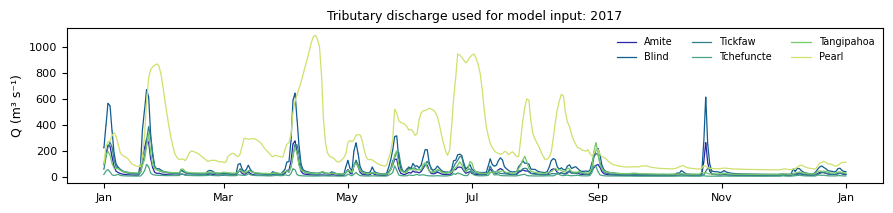

In [7]:
fig = fig_mod.plot_tributary_discharge(trib_by_year, YEARS, RIVERS_INFO)
plt.show()

### 5.3 Ocean boundary data

This section always loads ocean boundary water level.

If INCLUDE_SALINITY is True, salinity is loaded.
If INCLUDE_TEMPERATURE is True, ocean water temperature is loaded.

The plot includes only the variables that are active for this run.

Ocean boundary data 2017
  [water_level] primary: 8761305
    8761305: 8,760 / 8,760 hourly values (100.0%)
  [water_level] final: 8,760 / 8,760 hourly values (100.0%)

2017 means: WL=0.38 m (MLLW)


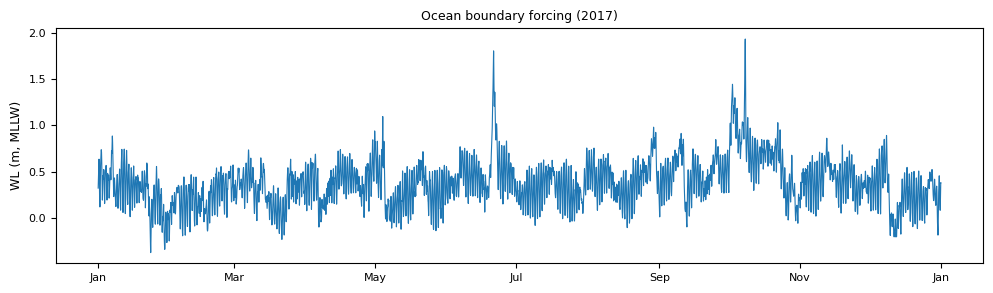

In [ ]:
wl_by_year = {}
sal_by_year = {}
watT_by_year = {}

for year in YEARS:
    print(f"Ocean boundary data {year}")

    wl_by_year[year] = load_water_level_with_backups(
        year,
        WL_STATION,
        WL_BACKUP_STATIONS,
        datum=NOAA_DATUM,
        gap_threshold_hours=WL_GAP_THRESHOLD_H,
    )

    if INCLUDE_SALINITY:
        sal_by_year[year] = load_salinity_with_backups(
            year,
            USGS_SALINITY_SITE,
            USGS_SALINITY_BACKUPS,
        )
    else:
        idx = hourly_index_for_year(year)
        sal_by_year[year] = pd.DataFrame({"datetime": idx, "salinity": np.nan})

    if INCLUDE_TEMPERATURE:
        watT_by_year[year] = load_water_temp_with_backups(
            year,
            USGS_WATER_TEMP_SITE,
            WT_BACKUP_STATIONS,
        )
    else:
        idx = hourly_index_for_year(year)
        watT_by_year[year] = pd.DataFrame({"datetime": idx, "water_temp": np.nan})

    summary = f"\n{year} means: WL={wl_by_year[year]['wl_lp'].mean():.2f} m ({NOAA_DATUM})"
    if INCLUDE_SALINITY:
        summary += f", Sal={sal_by_year[year]['salinity'].mean():.2f} ppt"
    if INCLUDE_TEMPERATURE:
        summary += f", WT={watT_by_year[year]['water_temp'].mean():.2f} degC"
    print(summary)

for year in YEARS:
    n_panels = 1 + int(INCLUDE_SALINITY) + int(INCLUDE_TEMPERATURE)
    fig, axes = plt.subplots(n_panels, 1, figsize=(10, 2.2 * n_panels + 0.8), sharex=True)
    if n_panels == 1:
        axes = [axes]

    panel_i = 0

    d_wl = wl_by_year[year]
    axes[panel_i].plot(d_wl["datetime"], d_wl["wl_lp"], lw=0.8, color="tab:blue")
    axes[panel_i].set_ylabel(f"WL (m, {NOAA_DATUM})")
    axes[panel_i].set_title(f"Ocean boundary forcing ({year})")
    panel_i += 1

    if INCLUDE_SALINITY:
        d_sal = sal_by_year[year]
        axes[panel_i].plot(d_sal["datetime"], d_sal["salinity"], lw=0.8, color="tab:orange")
        axes[panel_i].set_ylabel("Salinity (ppt)")
        panel_i += 1

    if INCLUDE_TEMPERATURE:
        d_wt = watT_by_year[year]
        axes[panel_i].plot(d_wt["datetime"], d_wt["water_temp"], lw=0.8, color="tab:cyan")
        axes[panel_i].set_ylabel("Water T (degC)")

    axes[-1].xaxis.set_major_locator(mdates.MonthLocator(interval=2))
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    fig.tight_layout()
    plt.show()

### 5.4 Wind speed + air pressure (Open-Meteo ERA5)


=== Wind + pressure (ERA5) 2017 ===
  [open-meteo] 2017: 8,760 rows fetched, annual means - H=79.8%, T=21.2C, CC=52.9%, GHI=190 W/m2, Wind=3.46 m/s, P=1017.3 hPa


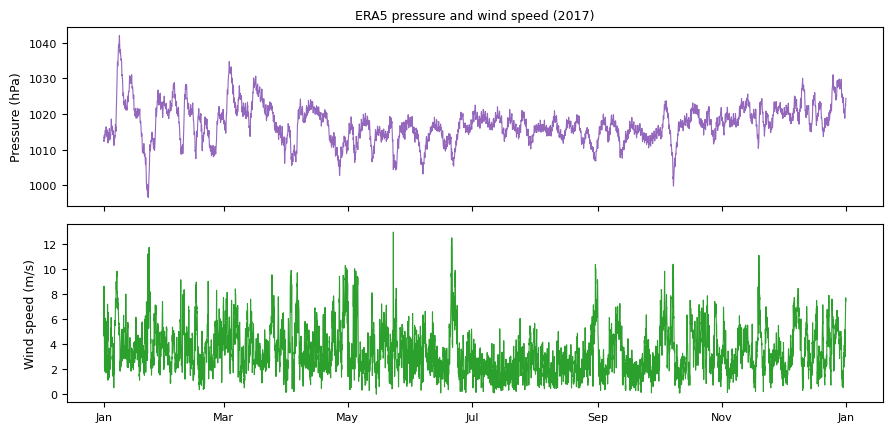

In [9]:
wind_by_year, pres_by_year = {}, {}
for year in YEARS:
    print(f"\n=== Wind + pressure (ERA5) {year} ===")
    om = load_openmeteo_hourly(year, OM_LAT, OM_LON, timeout=OM_TIMEOUT)
    if not om.empty:
        pres_by_year[year] = om[["datetime", "pressure"]].copy()
        wind_by_year[year] = om[["datetime", "wind_speed", "wind_direction"]].rename(
            columns={"wind_speed": "speed", "wind_direction": "direction"}
        ).copy()
    else:
        idx = hourly_index_for_year(year)
        pres_by_year[year] = pd.DataFrame({"datetime": idx, "pressure": np.nan})
        wind_by_year[year] = pd.DataFrame({"datetime": idx, "speed": np.nan, "direction": np.nan})

figs = fig_mod.plot_meteorology(pres_by_year, wind_by_year, YEARS)
for f in figs:
    plt.show()

### 5.5 Composite Temperature Data

This section is only needed when `INCLUDE_TEMPERATURE = True`.
It downloads the remaining met fields for `FlowFM_meteo.tim` (air temperature, humidity, cloudiness, solar radiation) and computes river temperature.

If temperature is off, this section is skipped and only discharge, water level, wind, and pressure forcings are prepared.

#### Download Met Data

In [10]:
openmeteo_by_year = {}
airT_by_year = {}
solar_by_year = {}

if INCLUDE_TEMPERATURE:
    for year in YEARS:
        print(f"\nERA5 met data {year}")
        om = load_openmeteo_hourly(year, OM_LAT, OM_LON, timeout=OM_TIMEOUT)
        openmeteo_by_year[year] = om
        if not om.empty:
            airT_by_year[year] = om[["datetime", "air_temp"]].copy()
            solar_by_year[year] = om[["datetime", "ghi"]].copy()
        else:
            idx = hourly_index_for_year(year)
            airT_by_year[year] = pd.DataFrame({"datetime": idx, "air_temp": np.nan})
            solar_by_year[year] = pd.DataFrame({"datetime": idx, "ghi": np.nan})

    figs = fig_mod.plot_era5(openmeteo_by_year, YEARS, OM_LAT, OM_LON)
    for f in figs:
        plt.show()
else:
    for year in YEARS:
        idx = hourly_index_for_year(year)
        openmeteo_by_year[year] = pd.DataFrame(
            {
                "datetime": idx,
                "humidity": np.nan,
                "air_temp": np.nan,
                "cloudiness": np.nan,
                "specific_humidity": np.nan,
                "ghi": np.nan,
            }
        )
        airT_by_year[year] = pd.DataFrame({"datetime": idx, "air_temp": np.nan})
        solar_by_year[year] = pd.DataFrame({"datetime": idx, "ghi": np.nan})
    print("Temperature disabled: skipped composite met download and plots.")

Temperature disabled: skipped composite met download and plots.


#### River inflow temperature derived from air temperature

This section derives tributary water temperature from ERA5 air temperature. This is only necessary if you are resolving the model for temperature.

Method: apply smoothing + lag + clipping from the notebook variable `RIVER_TEMP_CONFIG`.

In [11]:
_riv_cfg = RIVER_TEMP_CONFIG
LAG_DAYS = float(_riv_cfg.get("lag_days", 5))
SMOOTH_DAYS = float(_riv_cfg.get("smooth_days", 60))
RIV_T_MIN = float(_riv_cfg.get("tmin", 5))
RIV_T_MAX = float(_riv_cfg.get("tmax", 35))
RIV_T_OFFSET = float(_riv_cfg.get("offset", 0))

rivT_by_year = {}

if INCLUDE_TEMPERATURE:
    for year in YEARS:
        air = airT_by_year[year].set_index("datetime")["air_temp"]
        air.index = pd.to_datetime(air.index)
        rt = air_to_river_temp(
            air,
            LAG_DAYS,
            SMOOTH_DAYS,
            RIV_T_MIN,
            RIV_T_MAX,
            RIV_T_OFFSET,
        )
        rivT_by_year[year] = rt.rename("river_temp").rename_axis("datetime").reset_index()

    for year in YEARS:
        air = airT_by_year[year]
        rt = rivT_by_year[year]
        fig, ax = plt.subplots(figsize=(11, 3.6))
        ax.plot(air["datetime"], air["air_temp"], lw=0.8, color="tab:red", label="Air temp (ERA5)")
        ax.plot(rt["datetime"], rt["river_temp"], lw=1.4, color="tab:blue", label="Derived tributary water temp")
        ax.set_title(f"Air vs derived tributary water temperature ({year})")
        ax.set_ylabel("Temperature (degC)")
        ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
        ax.legend(loc="best", frameon=False)
        fig.tight_layout()
        plt.show()
else:
    for year in YEARS:
        idx = hourly_index_for_year(year)
        rivT_by_year[year] = pd.DataFrame({"datetime": idx, "river_temp": np.nan})
    print("Temperature disabled: skipped derived river temperature.")

Temperature disabled: skipped derived river temperature.


## 6. Convert everything to the same hourly grid

Turns variable DataFrames into one dict per year on a common hourly 
grid for plotting and file writing.

In [12]:
# Ensure all data dictionaries are populated.
# If you skipped any Section 5 cell, the data is downloaded here instead.

if "spillway_by_year" not in globals() or any(y not in spillway_by_year for y in YEARS):
    spillway_by_year = {
        y: load_spillway_csv(SPILLWAY_CSV, y)
        for y in YEARS
    }

if "trib_by_year" not in globals() or any(y not in trib_by_year for y in YEARS):
    trib_by_year = {}
    for year in YEARS:
        idx = hourly_index_for_year(year)
        pieces = []
        for r in RIVERS_INFO:
            name = r["name"].strip()
            g = load_tributary_scaled(r["site"], year, r["cfs_to_cms"], r["amplification"])
            if g.empty:
                g = pd.DataFrame({"datetime": idx, "Q_cms": 0.0, "name": name})
            else:
                g = to_hourly_spline(g.rename(columns={"Q_cms": "value"}), "value", idx, roll_win=3)
                g["Q_cms"] = g.pop("value")
                g["name"] = name
            pieces.append(g[["datetime", "Q_cms", "name"]])
        trib_by_year[year] = pd.concat(pieces, ignore_index=True)

if "wl_by_year" not in globals() or any(y not in wl_by_year for y in YEARS):
    wl_by_year = {
        y: load_water_level_with_backups(
            y,
            WL_STATION,
            WL_BACKUP_STATIONS,
            datum=NOAA_DATUM,
            gap_threshold_hours=WL_GAP_THRESHOLD_H,
        )
        for y in YEARS
    }

if "wind_by_year" not in globals() or any(y not in wind_by_year for y in YEARS):
    print("[assemble] Loading wind from ERA5")
    wind_by_year = {}
    for year in YEARS:
        om = load_openmeteo_hourly(year, OM_LAT, OM_LON, timeout=OM_TIMEOUT)
        if not om.empty and "wind_speed" in om.columns:
            wind_by_year[year] = om[["datetime", "wind_speed", "wind_direction"]].rename(
                columns={"wind_speed": "speed", "wind_direction": "direction"}
            ).copy()
        else:
            idx = hourly_index_for_year(year)
            wind_by_year[year] = pd.DataFrame({"datetime": idx, "speed": np.nan, "direction": np.nan})

if "pres_by_year" not in globals() or any(y not in pres_by_year for y in YEARS):
    print("[assemble] Loading pressure from ERA5")
    pres_by_year = {}
    for year in YEARS:
        om = load_openmeteo_hourly(year, OM_LAT, OM_LON, timeout=OM_TIMEOUT)
        if not om.empty:
            pres_by_year[year] = om[["datetime", "pressure"]].copy()
        else:
            idx = hourly_index_for_year(year)
            pres_by_year[year] = pd.DataFrame({"datetime": idx, "pressure": np.nan})

if INCLUDE_TEMPERATURE:
    if (
        "airT_by_year" not in globals()
        or "watT_by_year" not in globals()
        or any(y not in airT_by_year for y in YEARS)
    ):
        print("[assemble] Loading air and water temperature")
        airT_by_year, watT_by_year = {}, {}
        for year in YEARS:
            om = load_openmeteo_hourly(year, OM_LAT, OM_LON, timeout=OM_TIMEOUT)
            if not om.empty:
                airT_by_year[year] = om[["datetime", "air_temp"]].copy()
            else:
                idx = hourly_index_for_year(year)
                airT_by_year[year] = pd.DataFrame({"datetime": idx, "air_temp": np.nan})
            watT_by_year[year] = load_water_temp_with_backups(
                year,
                USGS_WATER_TEMP_SITE,
                WT_BACKUP_STATIONS,
            )

    if "openmeteo_by_year" not in globals() or any(y not in openmeteo_by_year for y in YEARS):
        openmeteo_by_year = {
            y: load_openmeteo_hourly(y, OM_LAT, OM_LON, timeout=OM_TIMEOUT)
            for y in YEARS
        }

    if "solar_by_year" not in globals() or any(y not in solar_by_year for y in YEARS):
        solar_by_year = {}
        for year in YEARS:
            d = openmeteo_by_year[year]
            if d.empty:
                idx = hourly_index_for_year(year)
                solar_by_year[year] = pd.DataFrame({"datetime": idx, "ghi": np.nan})
                continue
            ghi_available = d["ghi"].notna().sum()
            if ghi_available > 0.9 * len(d):
                solar_by_year[year] = d[["datetime", "ghi"]].copy()
            else:
                cloud_series = d.set_index("datetime")["cloudiness"].fillna(50.0)
                solar_by_year[year] = compute_solar_ghi_pvlib(year, OM_LAT, OM_LON, cloud_series)

    if "rivT_by_year" not in globals() or any(y not in rivT_by_year for y in YEARS):
        rivT_by_year = {
            y: pd.DataFrame({"datetime": hourly_index_for_year(y), "river_temp": np.nan})
            for y in YEARS
        }
else:
    idx_by_year = {y: hourly_index_for_year(y) for y in YEARS}
    airT_by_year = {y: pd.DataFrame({"datetime": idx_by_year[y], "air_temp": np.nan}) for y in YEARS}
    watT_by_year = {y: pd.DataFrame({"datetime": idx_by_year[y], "water_temp": np.nan}) for y in YEARS}
    openmeteo_by_year = {
        y: pd.DataFrame(
            {
                "datetime": idx_by_year[y],
                "humidity": np.nan,
                "air_temp": np.nan,
                "cloudiness": np.nan,
                "specific_humidity": np.nan,
            }
        )
        for y in YEARS
    }
    solar_by_year = {y: pd.DataFrame({"datetime": idx_by_year[y], "ghi": np.nan}) for y in YEARS}
    rivT_by_year = {y: pd.DataFrame({"datetime": idx_by_year[y], "river_temp": np.nan}) for y in YEARS}

if INCLUDE_SALINITY:
    if "sal_by_year" not in globals() or any(y not in sal_by_year for y in YEARS):
        sal_by_year = {
            y: load_salinity_with_backups(y, USGS_SALINITY_SITE, USGS_SALINITY_BACKUPS)
            for y in YEARS
        }
else:
    sal_by_year = {
        y: pd.DataFrame({"datetime": hourly_index_for_year(y), "salinity": np.nan})
        for y in YEARS
    }

# Pass all loaded data to the helper module and assemble the hourly model-input grid
hf.configure_hydromet_context(
    INCLUDE_TEMPERATURE=INCLUDE_TEMPERATURE,
    INCLUDE_SALINITY=INCLUDE_SALINITY,
    spillway_by_year=spillway_by_year,
    trib_by_year=trib_by_year,
    wl_by_year=wl_by_year,
    wind_by_year=wind_by_year,
    pres_by_year=pres_by_year,
    airT_by_year=airT_by_year,
    watT_by_year=watT_by_year,
    sal_by_year=sal_by_year,
    openmeteo_by_year=openmeteo_by_year,
    solar_by_year=solar_by_year,
    rivT_by_year=rivT_by_year,
)

data_by_year = {y: hf.assemble_year_stage1(y) for y in YEARS}
print(f"Assembled {len(data_by_year)} year(s): {list(data_by_year.keys())}")

Assembled 1 year(s): [2017]


# 7. Visualize Data Sources
This helps you see where the data is coming from that is being used in the model. 

,source,station_id,name,lat,lon,roles
0,NOAA,8747437,Bay Waveland Yacht Club,30.326342,-89.325800,water_level_backup
1,NOAA,8761305,Shell Beach,29.868110,-89.673250,water_level_primary
2,NOAA,8761927,New Canal Station,30.027222,-90.113335,met_primary
3,Open-Meteo,ERA5-grid,Open-Meteo ERA5 point,30.042500,-90.028300,meteo_grid


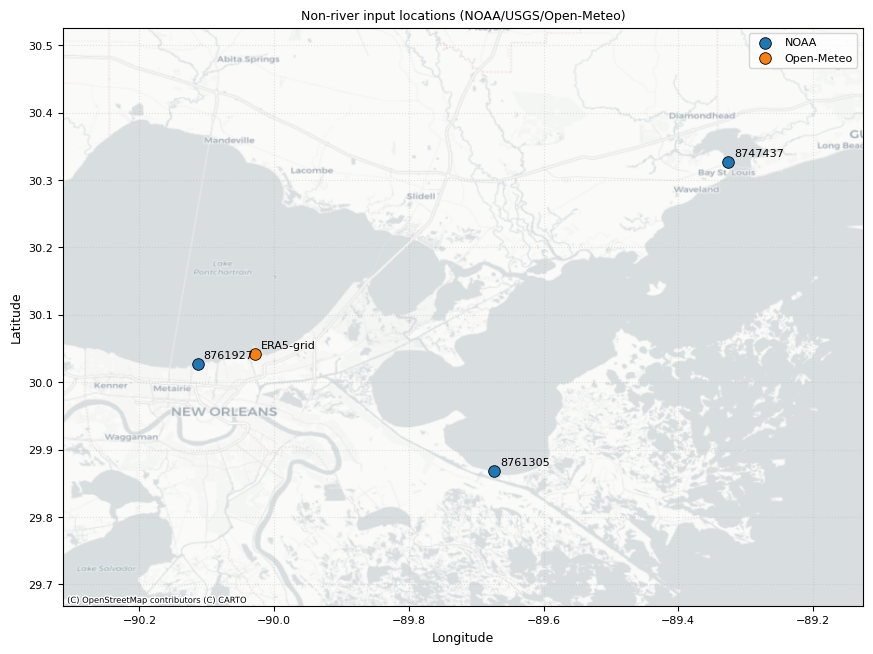

In [13]:
# Station locations map: shows every non-river input point (NOAA, USGS, Open-Meteo)
records_map = {}
_add_record(records_map, _fetch_noaa_station_meta(WL_STATION), "water_level_primary")
_add_record(records_map, _fetch_noaa_station_meta(MET_STATION), "met_primary")

if INCLUDE_TEMPERATURE:
    for sid in WT_BACKUP_STATIONS:
        _add_record(records_map, _fetch_noaa_station_meta(sid), "water_temp_backup")
    _add_record(records_map, _fetch_usgs_site_meta(USGS_WATER_TEMP_SITE), "water_temp_primary")

for sid in WL_BACKUP_STATIONS:
    _add_record(records_map, _fetch_noaa_station_meta(sid), "water_level_backup")

if INCLUDE_SALINITY:
    _add_record(records_map, _fetch_usgs_site_meta(USGS_SALINITY_SITE), "salinity_primary")
    for sid in USGS_SALINITY_BACKUPS:
        _add_record(records_map, _fetch_usgs_site_meta(sid), "salinity_backup")

_add_record(records_map, {
    "source": "Open-Meteo", "station_id": "ERA5-grid",
    "name": "Open-Meteo ERA5 point", "lat": float(OM_LAT), "lon": float(OM_LON),
}, "meteo_grid")

loc_df = pd.DataFrame(records_map.values())
if loc_df.empty:
    raise RuntimeError("No station metadata could be resolved.")
loc_df["roles"] = loc_df["roles"].apply(lambda r: ", ".join(sorted(set(r))))
loc_df = loc_df.sort_values(["source", "station_id"]).reset_index(drop=True)
display(loc_df[["source", "station_id", "name", "lat", "lon", "roles"]])

fig, ax = plt.subplots(figsize=(8.8, 7.2))
colors = {"NOAA": "tab:blue", "USGS": "tab:green", "Open-Meteo": "tab:orange"}
for src, grp in loc_df.groupby("source"):
    ax.scatter(grp["lon"], grp["lat"], s=70, c=colors.get(src, "tab:gray"),
               label=src, edgecolor="black", linewidth=0.6, zorder=3)
for _, r in loc_df.iterrows():
    ax.annotate(r["station_id"], (r["lon"], r["lat"]),
                xytext=(4, 4), textcoords="offset points", fontsize=8, zorder=4)

xpad, ypad = 0.2, 0.2
ax.set_xlim(loc_df["lon"].min() - xpad, loc_df["lon"].max() + xpad)
ax.set_ylim(loc_df["lat"].min() - ypad, loc_df["lat"].max() + ypad)
try:
    import contextily as ctx
    ctx.add_basemap(ax, crs="EPSG:4326", source=ctx.providers.CartoDB.Positron,
                    attribution_size=6, alpha=0.9, zorder=0)
except Exception as exc:
    print(f"[warn] basemap unavailable: {exc}")

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Non-river input locations (NOAA/USGS/Open-Meteo)")
ax.grid(True, linestyle=":", alpha=0.35, zorder=2)
ax.legend(loc="best")
ax.set_aspect("equal", adjustable="box")
plt.tight_layout()
plt.show()

## 8. Excel export

One workbook per year, one sheet per variable. For QA and sharing.

In [14]:
for year in YEARS:
    out_xlsx = TABLE_DIR / f"hydromet_{year}.xlsx"
    sheets = build_sheets(year, data_by_year[year])
    with pd.ExcelWriter(out_xlsx, engine="openpyxl") as xlw:
        for sheet_name, df in sheets.items():
            df.to_excel(xlw, sheet_name=_safe_sheet_name(sheet_name), index=False)
    print(f"Excel saved: {out_xlsx} ({len(sheets)} sheets)")

Excel saved: C:\Users\hydro\Lake_Pontchartrain_Model\outputs\tables\hydromet_2017.xlsx (5 sheets)


## 9. Apply Smoothing to Met Data
Optional step, but is helpful for running the model with composite temperature. 

In [15]:
MET_SMOOTHING_HOURS = 1
WIND_SMOOTHING_HOURS = 1
hf.configure_hydromet_context(MET_SMOOTHING_HOURS=MET_SMOOTHING_HOURS)

wind_by_year = {}
pres_by_year = {}
airT_by_year = {}
openmeteo_by_year = {}
solar_by_year = {}

for year in YEARS:
    idx = hourly_index_for_year(year)

    # Load all ERA5 data once
    openmeteo_raw = load_openmeteo_hourly(year, OM_LAT, OM_LON, timeout=OM_TIMEOUT)

    # Wind: smooth speed and circular direction by averaging u/v over the chosen window
    if not openmeteo_raw.empty and "wind_speed" in openmeteo_raw.columns:
        wind_hourly = smooth_hourly_wind(
            openmeteo_raw[["datetime", "wind_speed", "wind_direction"]].rename(
                columns={"wind_speed": "speed", "wind_direction": "direction"}
            ),
            idx,
            win=WIND_SMOOTHING_HOURS,
        )
    else:
        wind_hourly = pd.DataFrame({"datetime": idx, "speed": np.nan, "direction": np.nan})
    _ensure_naive_datetime(wind_hourly, "datetime")
    wind_by_year[year] = wind_hourly

    # Pressure: use ERA5 pressure with rolling mean
    if not openmeteo_raw.empty and "pressure" in openmeteo_raw.columns:
        pres_by_year[year] = _smooth_hourly_met(
            openmeteo_raw[["datetime", "pressure"]], "pressure", win=MET_SMOOTHING_HOURS
        )
    else:
        pres_by_year[year] = pd.DataFrame({"datetime": idx, "pressure": np.nan})
    _ensure_naive_datetime(pres_by_year[year], "datetime")

    if INCLUDE_TEMPERATURE:
        # Air temperature from ERA5
        if not openmeteo_raw.empty and "air_temp" in openmeteo_raw.columns:
            airT_by_year[year] = _smooth_hourly_met(
                openmeteo_raw[["datetime", "air_temp"]], "air_temp", win=MET_SMOOTHING_HOURS
            )
        else:
            airT_by_year[year] = pd.DataFrame({"datetime": idx, "air_temp": np.nan})
        _ensure_naive_datetime(airT_by_year[year], "datetime")

        # Composite met drivers
        openmeteo_smoothed = (
            _smooth_hourly_met(openmeteo_raw[["datetime", "humidity"]], "humidity")
            .merge(_smooth_hourly_met(openmeteo_raw[["datetime", "air_temp"]], "air_temp"), on="datetime")
            .merge(_smooth_hourly_met(openmeteo_raw[["datetime", "cloudiness"]], "cloudiness"), on="datetime")
        )
        _ensure_naive_datetime(openmeteo_smoothed, "datetime")

        pressure_for_q = (
            pres_by_year[year].set_index("datetime")["pressure"]
            .reindex(openmeteo_smoothed["datetime"])
            .interpolate(method="time", limit_direction="both")
        )
        if pressure_for_q.isna().all():
            pressure_for_q = pd.Series(1013.25, index=openmeteo_smoothed.index)
        else:
            pressure_for_q = pressure_for_q.fillna(pressure_for_q.median())

        openmeteo_smoothed["specific_humidity"] = _relative_to_specific_humidity(
            openmeteo_smoothed["humidity"].values,
            openmeteo_smoothed["air_temp"].values,
            pressure_for_q.values,
        )

        # Solar GHI: use ERA5 directly if available, fall back to pvlib clear-sky model
        ghi_available = openmeteo_raw["ghi"].notna().sum()
        if ghi_available > 0.9 * len(openmeteo_raw):
            solar_by_year[year] = openmeteo_raw[["datetime", "ghi"]].copy()
        else:
            cloud_series = openmeteo_smoothed.set_index("datetime")["cloudiness"].fillna(50.0)
            solar_by_year[year] = compute_solar_ghi_pvlib(year, OM_LAT, OM_LON, cloud_series)
        _ensure_naive_datetime(solar_by_year[year], "datetime")

        openmeteo_by_year[year] = openmeteo_smoothed.merge(
            solar_by_year[year][["datetime", "ghi"]], on="datetime", how="left"
        )
    else:
        airT_by_year[year] = pd.DataFrame({"datetime": idx, "air_temp": np.nan})
        solar_by_year[year] = pd.DataFrame({"datetime": idx, "ghi": np.nan})
        openmeteo_by_year[year] = pd.DataFrame(
            {
                "datetime": idx,
                "humidity": np.nan,
                "air_temp": np.nan,
                "cloudiness": np.nan,
                "specific_humidity": np.nan,
                "ghi": np.nan,
            }
        )

if not INCLUDE_TEMPERATURE:
    print("Temperature disabled: meteo composite smoothing skipped; wind and pressure were still rebuilt.")

# Reassemble the full hourly grid with updated forcings
hf.configure_hydromet_context(
    INCLUDE_TEMPERATURE=INCLUDE_TEMPERATURE,
    INCLUDE_SALINITY=INCLUDE_SALINITY,
    spillway_by_year=spillway_by_year,
    trib_by_year=trib_by_year,
    wl_by_year=wl_by_year,
    wind_by_year=wind_by_year,
    pres_by_year=pres_by_year,
    airT_by_year=airT_by_year,
    watT_by_year=watT_by_year,
    sal_by_year=sal_by_year,
    openmeteo_by_year=openmeteo_by_year,
    solar_by_year=solar_by_year,
    rivT_by_year=rivT_by_year,
)

data_by_year = {y: hf.assemble_year_stage2(y) for y in YEARS}
print(
    f"Forcings rebuilt with {MET_SMOOTHING_HOURS}-hour scalar smoothing and {WIND_SMOOTHING_HOURS}-hour circular wind smoothing for years {YEARS}."
)

  [open-meteo] 2017: 8,760 rows fetched, annual means - H=79.8%, T=21.2C, CC=52.9%, GHI=190 W/m2, Wind=3.46 m/s, P=1017.3 hPa
Temperature disabled: meteo composite smoothing skipped; wind and pressure were still rebuilt.
Forcings rebuilt with 1-hour scalar smoothing and 1-hour circular wind smoothing for years [2017].


## 10. Write Delft3D-FM input files

One folder is written per year under `outputs/dfm_forcings/<year>/` with set of
boundary files for `FlowFM_bnd.ext` and `FlowFM.ext`:

```
outputs/dfm_forcings/<year>/
├── Discharge.bc              # 7 blocks, one per polyline (6 rivers + spillway)
├── WaterLevel.bc             # 3 blocks, one per SeaBoundary support point
├── Temperature.bc            # 17 blocks (every polyline × every support point)
├── Salinity.bc               # 15 blocks (as Temperature, minus PearlRiver's 2)
├── windxy.tim                # 3 columns: time, wind speed (m/s), wind direction (°)
├── atmosphericpressure.tim   # 2 columns: time, pressure (hPa)
└── FlowFM_meteo.tim          # 5 columns: time, humidity, airT, cloud, GHI
```


### File format conventions (match your 2021 model exactly)

`.bc` files use the Deltares GUI format: lowercase `[forcing]`, title-case field
names with a hyphen in `Time-interpolation`, 32-column padding, integer
**seconds** since RefDate (2001-01-01), no `offset` / `factor` lines:

```
[forcing]
Name                            = AmiteRiver
Function                        = timeseries
Time-interpolation              = linear
Quantity                        = time
Unit                            = seconds since 2001-01-01 00:00:00
Quantity                        = dischargebnd
Unit                            = m3/s
378691200  12.82989456
378694800  12.74603904
...
```

`.tim` files use a different convention: **minutes** since RefDate, scientific
notation with 7 decimal places, single-space separator, no comment header:

```
6.3115200e+06 3.9600000e+00 3.0970000e+02
6.3115800e+06 4.0800000e+00 3.0825000e+02
...
```

### Block naming convention

- **Discharge**: one `[forcing]` block per polyline, named with the polyline
  name (`AmiteRiver`, `BlindRiver`, … `BonnetCarreSpillway`). Discharge is a
  cross-section total, so one value per polyline.
- **Water level, Temperature, Salinity**: one `[forcing]` block per support
  point, named `PolylineName_NNNN` (e.g. `SeaBoundary_0001` through
  `SeaBoundary_0003`, `AmiteRiver_0001`, `AmiteRiver_0002`). Same time series
  replicated at each support point — uniform along the polyline.

In [16]:
if DFM_WRITE:
    print(
        f"Writing forcings with toggles: temperature={INCLUDE_TEMPERATURE}, salinity={INCLUDE_SALINITY}"
    )
    for year in YEARS:
        print(f"{year}")
        out = write_dfm_year(year, data_by_year[year])
        print(f"Files in {out}:")
        for f in sorted(out.iterdir()):
            print(f"    {f.name:<30s}  {f.stat().st_size:>8,} bytes")
else:
    print("DFM file writing disabled (set dfm.write_files: true in config to enable)")

Writing forcings with toggles: temperature=False, salinity=False
2017
  wrote Discharge.bc  (7 blocks)
  wrote WaterLevel.bc  (3 blocks)
  [skip] temperature disabled
  [skip] salinity disabled
  wrote windxy.tim
  wrote atmosphericpressure.tim
  [skip] composite meteo disabled (temperature off)
Files in C:\Users\hydro\Lake_Pontchartrain_Model\outputs\dfm_forcings\2017:
    atmosphericpressure.tim          254,040 bytes
    Discharge.bc                    1,732,431 bytes
    WaterLevel.bc                    827,608 bytes
    windxy.tim                       376,680 bytes


#### What to do with the files

1. **Copy the new `.bc` and `.tim` files** from `outputs/dfm_forcings/<year>/`
   into your Delft3D-FM model folder (same folder as `FlowFM.mdu`). They will
   overwrite the 2021 versions with identical names — which is what you want.

2. **`FlowFM.ext` and `FlowFM_bnd.ext` need no edits**: they reference file
   *names*, and every name still matches. The only exception is if you are adding 
   composite temperature, then you need to add _solarradiation to the the end of
   **QUANTITIY** in `FlowFM.ext`.